In [1]:
from datetime import date
today = date.today()
print('Última corrida el',today)

Última corrida el 2024-05-01


In [2]:
from astropy.io import fits 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.wcs import utils
import astropy.units as u
import astropy.coordinates as coords
from photutils.aperture import CircularAperture,aperture_photometry
from astropy.io import fits
from scipy.stats import norm
from scipy.optimize import curve_fit
from numpy import asarray as ar,exp
import scipy.integrate as integrate
from cycler import cycler
import matplotlib as mpl
import os

In [3]:
# defino parametros generales para los graficos que despues puedo modificar individualmente

styling = {
        'lines.linewidth' : 2,
        'font.family' : 'serif',
        'axes.prop_cycle' : cycler('color', ['#EE6666', '#3388BB', '#9988DD',
                 '#EECC55', '#88BB44', '#FFBBBB']),
        'axes.labelsize' : 25,
        'legend.fontsize' : 20,
        "xtick.labelsize": 20,
        "ytick.labelsize": 20,
        'ytick.major.size' : 5,
        'ytick.minor.size' : 4,
        'xtick.major.size' : 5,
        'xtick.minor.size' : 4,
        'xtick.direction' : 'inout',
        'ytick.direction' : 'inout',  
}

mpl.rcParams.update(styling)

In [5]:
bas = pd.read_csv('../../../2023/pne/ngc4472left/ngc4472_dat.cat')

In [6]:
#function to generate an arbitrary wl range of MUSE. Full coverage: (3721)*1.25+4699.625
def wl(N, crpix, crdelt, crval):
    """
    N: numero del slice
    crpix: reference slice de inicio
    crdelt: delta lambda por cada slice
    crval: lambda de referencia/inicio
    """
    return (N+1-crpix)*crdelt + crval

CRPIX1 = 1
CRDEL1 = 1.25
CRVAL1 = float(bas['ngc4472.fits'][2])

In [7]:
CRVAL1

4749.84326171875

In [26]:
roth = pd.read_csv('slices/ngc4472_pne.cat',delim_whitespace=True,names=['ra','dec','x','y','flux','cen'])

In [27]:
spec = pd.read_csv('slices/ngc4472_aper_phot.csv')

ar = []
for i in range(len(roth['x'])):
    x = roth['x'][i]
    y = roth['y'][i]
    x0 = roth['x']
    y0 = roth['y']

    if(np.any((np.sqrt(np.power((x-x0),2)+np.power((y-y0),2)))<0.5)):
        ind = np.where((np.sqrt(np.power((x-x0),2)+np.power((y-y0),2)))<0.5)
        for j in range(len(ind[0])):
            if(ind[0][j]!=i):
                if(np.all(ind[0][j]!=ar)):
                    ar.append(i)   
            
roth = roth.drop(ar)
roth = roth.reset_index(drop=True)
roth = roth.sort_values(by=['x','y'])
roth = roth.reset_index(drop=True)
len(roth)            

np.savetxt('roth_dropped.txt',roth)

In [28]:
#flux and eflux values will correstond to 
n = 2  #star id-1 (-1 because of python)
flux = spec.values[n, 3::2]
eflux = spec.values[n, 4::2]
slices_to_extract = np.arange(len(flux))
w = wl(N=slices_to_extract, crpix=CRPIX1, crdelt=CRDEL1, crval=CRVAL1) #creates the array of wl to use with the extracted spectrum
min(w)

4749.84326171875

In [29]:
CRVAL1

4749.84326171875

In [30]:
w = w/(1+0.003272)
min(w)

4734.352460468099

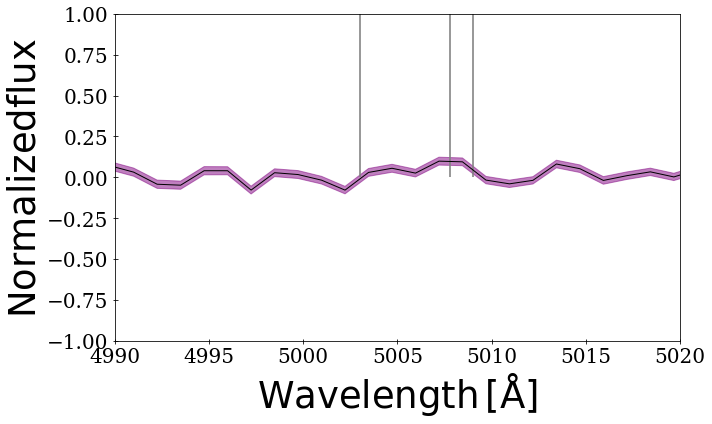

In [31]:
plt.figure(figsize=(10,6))

shift = 0.0 #pix/AA

plt.xlim(4990, 5020)
#plt.subplot(2,1,1)
plt.plot(w-shift, flux/np.max(flux), color='k', lw=1)
plt.fill_between(w-shift, (flux-eflux)/np.max(flux), (flux+eflux)/np.max(flux), color='purple', alpha=0.5)
plt.vlines(x=5007.8, ymin=0, ymax=1.1, color='gray', alpha=0.8)
plt.vlines(x=5006-3, ymin=0, ymax=1.1, color='gray', alpha=0.8)
plt.vlines(x=5006+3, ymin=0, ymax=1.1, color='gray', alpha=0.8)

plt.ylim(-1, 1)
plt.ylabel(r'${\rm Normalized flux}$', size=37)
plt.xlabel(r'${\rm Wavelength\,[\AA]}$', size=37)

plt.tight_layout()

#plt.savefig('full.png')


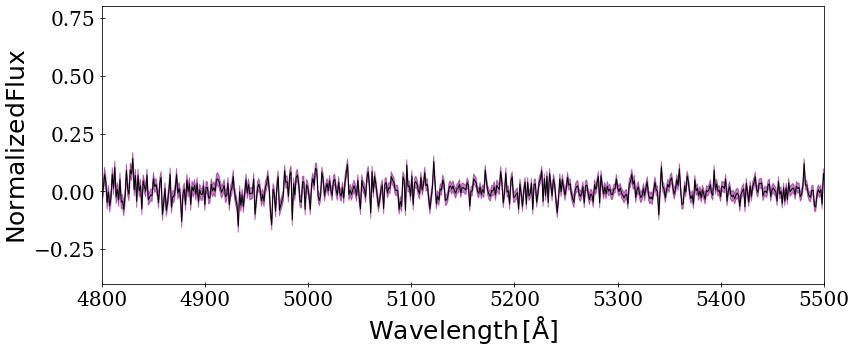

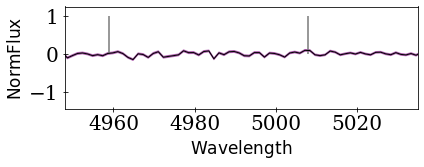

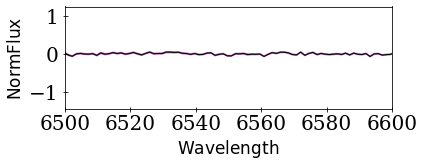

In [32]:
plt.figure(figsize=(12,5))

shift = 0. #pix/AA

plt.xlim(4800, 5500)
#plt.subplot(2,1,1)
plt.plot(w-shift, flux/np.max(flux), color='k', lw=1)
plt.fill_between(w-shift, (flux-eflux)/np.max(flux), (flux+eflux)/np.max(flux), color='purple', alpha=0.5)
#plt.vlines(x=5007-3, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)
#plt.vlines(x=5007+3, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)

plt.ylim(-0.4, 0.8)
plt.ylabel(r'${\rm Normalized Flux}$', size=25)
plt.xlabel(r'${\rm Wavelength\,[\AA]}$', size=25)

plt.tight_layout()

plt.savefig('short.png')

plt.show()

#center on OIII
shift = 0. #pix/AA
plt.subplot(2,1,1)
plt.plot(w-shift, flux/np.max(flux), color='k', lw=1)
plt.fill_between(w-shift, (flux-eflux)/np.max(flux), (flux+eflux)/np.max(flux), color='purple', alpha=0.5)
plt.vlines(x=5008, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)
plt.vlines(x=4959, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)
#plt.vlines(x=5008-3, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)
#plt.vlines(x=5008+3, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)
plt.savefig('spectrfull.png')

plt.xlim(4948, 5035)
#plt.ylim(0, 1000)
plt.ylabel(r'${\rm Norm Flux}$', size=17)
plt.xlabel(r'${\rm Wavelength}$', size=17)

plt.tight_layout()
plt.savefig('spectr.png')
plt.show()

# center on Halpha
shift = 0. #pix/AA
plt.subplot(2,1,1)
plt.plot(w-shift, flux/np.max(flux), color='k', lw=1)
plt.fill_between(w-shift, (flux-eflux)/np.max(flux), (flux+eflux)/np.max(flux), color='purple', alpha=0.5)
#plt.vlines(x=6564.61, ymin=0.0, ymax=1.0, color='gray', alpha=0.8)
plt.xlim(6500, 6600)
#plt.ylim(0.3, 0.7)
plt.ylabel(r'${\rm Norm Flux}$', size=17)
plt.ylabel(r'${\rm Norm Flux}$', size=17)
plt.xlabel(r'${\rm Wavelength}$', size=17)

plt.tight_layout()
plt.savefig('spectr_h.png')

plt.show()



In [33]:
roth['cen'] = roth['cen']/(1+0.003272)

In [34]:
idf = np.zeros(len(spec['id']))

mag = np.zeros(len(spec['id']))
mag2 = np.zeros(len(spec['id']))
flu = np.zeros(len(spec['id']))
m_o = np.zeros(len(spec['id']))
emo = np.zeros(len(spec['id']))
m_o2 = np.zeros(len(spec['id']))
flu2 = np.zeros(len(spec['id']))
flu3 = np.zeros(len(spec['id']))
eflu = np.zeros(len(spec['id']))
eflu2 = np.zeros(len(spec['id']))
eflu3 = np.zeros(len(spec['id']))
emag = np.zeros(len(spec['id']))
emag2 = np.zeros(len(spec['id']))

                 
for i in range(len(spec['id'])):
    
    flux = spec.values[i, 3::2]
    
    
    h_al = 6564.61

    ind = np.where(np.abs((w-h_al))<0.625)
    start = ind[0][0]-3
    end = ind[0][0]+3
    h_fil = flux[start:end]
    h_err = eflux[start:end]
                 
    m_h = np.sum(h_fil,axis=0)
    emh = np.sqrt(np.sum(np.power(h_err,2),axis=0))

    oiii = 5008

    ind = np.where(np.abs((w-roth['cen'][i]))<0.625)

    start = ind[0][0]-3
    end = ind[0][0]+3
    o_fil = flux[start:end]
    o_err = eflux[start:end]
    
    emo[i] = np.sqrt(np.sum(np.power(o_err,2),axis=0))
    m_o[i] = np.sum(o_fil,axis=0)
    
    
    m_o2[i] = flux[ind[0][0]]


    nii = 6585.27

    ind = np.where(np.abs((w-nii))<0.625)
    start = ind[0][0]-3
    end = ind[0][0]+3
    n_fil = flux[start:end]
    n_err = eflux[start:end]
    
    m_n = np.sum(n_fil,axis=0)
    emn = np.sqrt(np.sum(np.power(n_err,2),axis=0))
    
    sii = 6716

    ind = np.where(np.abs((w-sii))<0.625)
    start = ind[0][0]-3
    end = ind[0][0]+3
    s_fil = flux[start:end]
    s_err = eflux[start:end]
    
    m_s = np.sum(s_fil,axis=0)
    ems = np.sqrt(np.sum(np.power(s_err,2),axis=0))
    
    sii2 = 6731

    ind = np.where(np.abs((w-sii2))<0.625)
    start = ind[0][0]-3
    end = ind[0][0]+3
    s_fil2 = flux[start:end]
    s2_err = eflux[start:end]

    m_s2 = np.sum(s_fil2,axis=0)
    ems2 = np.sqrt(np.sum(np.power(s2_err,2),axis=0))
    

    if(m_o[i]>0):
        mag[i] = -2.5*np.log10(m_o[i]*np.power(10.0,-20))-13.74
        emag[i] = (2.5/np.log(10))*(emo[i]/m_o[i])
        mag2[i] = -2.5*np.log10(m_o2[i]*np.power(10.0,-20))-13.74
        flu[i] = m_o[i]/(m_h+m_n)
        eflu[i] = np.sqrt(np.power(emo[i]/m_o[i],2)+np.power(emh/m_h,2)+np.power(emn/m_n,2))
        flu2[i] = m_h/m_n
        eflu2[i] = np.sqrt(np.power(emh/m_h,2)+np.power(emn/m_n,2))
        flu3[i] = m_h/(m_s+m_s2)
        eflu3[i] = np.sqrt(np.power(emh/m_h,2)+np.power(ems/m_s,2)+np.power(ems2/m_s2,2))
        idf[i] = spec['id'][i]
    else:
        mag[i] = 99
        flu[i] = 0

/home/anaines/anaconda3/envs/py36/lib/python3.6/site-packages/ipykernel_launcher.py:87: RuntimeWarning: invalid value encountered in log10


In [35]:
emag

array([0.18995226, 0.34476076, 0.217847  , 0.19604869, 0.        ,
       0.11371602, 0.11126197, 0.17514946, 0.22800445, 0.27101952,
       0.10928766, 0.15398779, 0.16965793, 0.65261559, 0.32313229,
       0.26465993, 0.1841663 , 0.5884164 , 0.30547424, 0.13662958,
       0.17313162, 0.18011135, 0.38012465])

In [36]:
from scipy import stats
x = mag
y = mag2
# Linear regression model
gradient, intercept, r_value, p_value, slope_std_error = stats.linregress(x, y)
predict_y = gradient * x + intercept
# Associated error
pred_error = y - predict_y
degrees_of_freedom = len(x) - 2
residual_std_error = np.sqrt(np.sum(pred_error**2) / degrees_of_freedom)

(nan, nan)

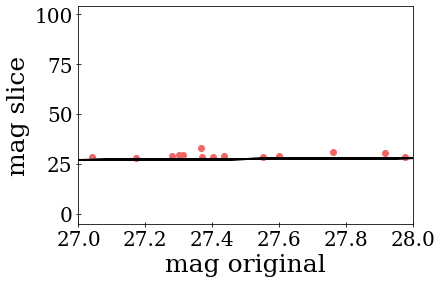

In [37]:
plt.scatter(mag,mag2)
plt.xlabel('mag original')
plt.ylabel('mag slice')
plt.plot(mag2, mag2 , label='Line of best fit')
plt.plot(mag, mag, c='black')
plt.xlim(27,28)
#plt.plot(x,x+1.2)
gradient,intercept

In [38]:
new = np.asarray([roth['x'],roth['y'],roth['ra'],roth['dec'],roth['cen'],mag,m_o])
new = new.transpose()
np.savetxt('catalogo.txt',new)

<span style='color:darkolivegreen;font-weight:bold'> CHECK DISTANCE MODULUS BELOW </span>

In [39]:
condition = np.log10(flu)>(-0.37*((mag)-(31.12))-1.16)
condition2 = (flu<4)
condition3 = (eflu<600)

mag2 = mag[condition&condition2]
mag2

/home/anaines/anaconda3/envs/py36/lib/python3.6/site-packages/ipykernel_launcher.py:1: RuntimeWarning: divide by zero encountered in log10
  """Entry point for launching an IPython kernel.
/home/anaines/anaconda3/envs/py36/lib/python3.6/site-packages/ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in log10
  """Entry point for launching an IPython kernel.


array([27.40072924, 28.04784914, 27.55056327, 26.81998493, 27.76083852,
       28.62832997, 27.91655453, 27.30005903])

In [40]:
pne = np.asarray([roth['x'][condition&condition2],roth['y'][condition&condition2],roth['ra'][condition&condition2],roth['dec'][condition&condition2],roth['cen'][condition&condition2],mag[condition&condition2],m_o[condition&condition2],idf[condition&condition2]])
pne = pne.transpose()
np.savetxt('pne.txt',pne)
pne

array([[6.41334000e+01, 7.49942600e+02, 1.87445020e+02, 8.02298420e+00,
        5.00506876e+03, 2.74007292e+01, 3.49710203e+03, 1.00000000e+00],
       [1.25590700e+02, 5.27911600e+02, 1.87441572e+02, 8.01064920e+00,
        5.00368978e+03, 2.80478491e+01, 1.92690519e+03, 2.00000000e+00],
       [1.25728500e+02, 5.81400200e+02, 1.87441564e+02, 8.01362080e+00,
        5.00674765e+03, 2.75505633e+01, 3.04631418e+03, 3.00000000e+00],
       [2.45647800e+02, 5.12851600e+02, 1.87434837e+02, 8.00981250e+00,
        5.00516719e+03, 2.68199849e+01, 5.97043575e+03, 7.00000000e+00],
       [3.47020400e+02, 2.04547800e+02, 1.87429150e+02, 7.99268450e+00,
        5.00460891e+03, 2.77608385e+01, 2.50994723e+03, 1.60000000e+01],
       [3.47806000e+02, 2.03625200e+02, 1.87429105e+02, 7.99263320e+00,
        5.00512897e+03, 2.86283300e+01, 1.12893260e+03, 1.80000000e+01],
       [3.55707200e+02, 4.54696600e+02, 1.87428662e+02, 8.00658160e+00,
        5.00495713e+03, 2.79165545e+01, 2.17459401e+03, 1.

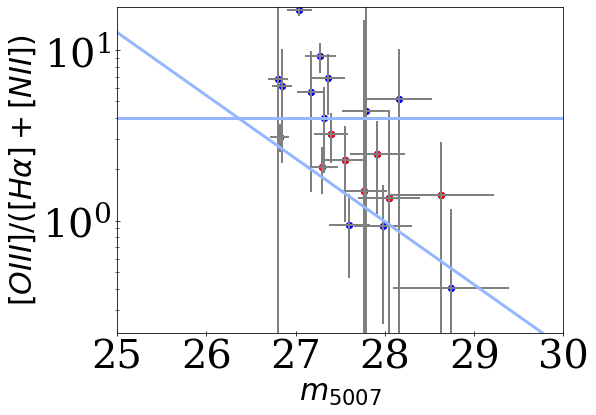

In [41]:
fig,ax = plt.subplots(figsize=(8,6))

magarr = np.arange(20,35)


plt.errorbar(mag[condition3],flu[condition3],xerr=emag[condition3],yerr=eflu[condition3],color='grey',fmt='none')

plt.scatter(mag[condition3],flu[condition3],s=40,color='blue')
plt.scatter(mag[condition&condition2],flu[condition&condition2],s=40,color='red')


y = np.power(10,-0.37*((magarr)-(31.12))-1.16)
plt.yscale('log',base=10)
#plt.vlines(31.2-4.5,0,10)
plt.plot(magarr,y,color='#95b7ff',linewidth=3)
plt.hlines(4,20,30,color='#95b7ff',linewidth=3)
plt.xlim(25,30)
plt.ylim(0.22,18)

plt.xticks(fontsize=40)
plt.yticks(fontsize=40)
plt.ylabel(r'$[OIII]/([H\alpha]+[NII])$',fontsize=30)
plt.xlabel('$m_{5007}$',fontsize=30)
plt.savefig('diagnostic.png',bbox_inches='tight')

In [42]:
len(pne)

8

/home/anaines/anaconda3/envs/py36/lib/python3.6/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in log10
  This is separate from the ipykernel package so we can avoid doing imports until


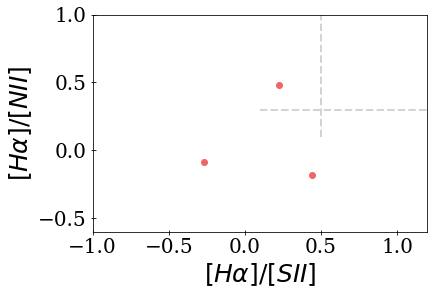

In [43]:
fig,ax = plt.subplots(figsize=(6,4))

plt.scatter(np.log10(flu3[condition&condition2]),np.log10(flu2[condition&condition2]))


#y = np.power(10,-0.37*((magarr)-(31))-1.16)
#plt.yscale('log',base=10)
#plt.xscale('log',base=10)
plt.hlines(0.3,0.1,10,linestyle='dashed',color='lightgrey')

plt.vlines(0.5,0.1,10,linestyle='dashed',color='lightgrey')
#plt.plot(flu2,flu3,color='#95b7ff')
#plt.hlines(4,26,30,color='#95b7ff')
plt.xlim(-1,1.2)
plt.ylim(-0.6,1)

plt.ylabel(r'$[H\alpha]/[NII]$')
plt.xlabel(r'$[H\alpha]/[SII]$')
plt.savefig('diagnostic2.png',bbox_inches='tight')

In [44]:
from astropy.io import fits

In [29]:
min(mag2)

27.984917877840438

In [88]:
binw = np.arange(25.75,28,0.3)

def pnlf(x,c,b):
    return c*exp(-b*x)*(1-exp(3*((26.83)-x)))

def PNLF_analytic(m5007, mag, c1):
    return c1*np.exp(-0.302*mag)*np.exp(0.302*m5007)*(1.- np.exp(3*(-4.51 + mag - m5007)))


histp = list(np.histogram(mag2,bins=binw))

mids = 0.5*(binw[1:] + binw[:-1])

popt,pcov = curve_fit(PNLF_analytic,mids,histp[0],p0=[31,0.6])
x0 = np.arange(26,27.5,0.1)
histp

[array([0, 0, 0, 0, 0, 0, 0]),
 array([25.75, 26.05, 26.35, 26.65, 26.95, 27.25, 27.55, 27.85])]

In [89]:
min(mag2)

27.984917877840438

In [90]:
histp

[array([0, 0, 0, 0, 0, 0, 0]),
 array([25.75, 26.05, 26.35, 26.65, 26.95, 27.25, 27.55, 27.85])]

In [91]:
compl

,magnitude,detection_completeness
0,26.65,0.900000
1,26.95,0.880215
2,27.25,0.747324
3,27.55,0.668020
4,27.85,0.614129
5,28.15,0.457044
6,28.45,0.259291
7,28.75,0.161261
8,29.05,0.154223


In [92]:
compl = pd.read_csv('completeness/compl_mag',names=['magnitude','detection_completeness'],delim_whitespace=True)
compl['detection_completeness'][0] = 0.9
#compl['magnitude'] = compl['magnitude']-1

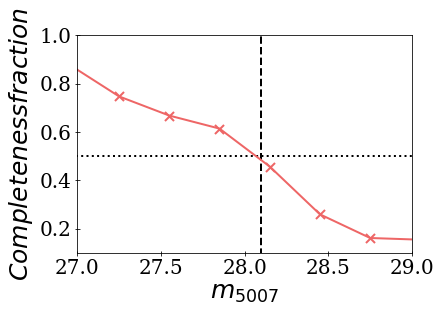

In [93]:
from scipy import interpolate
f1 = interpolate.interp1d(compl['magnitude'],compl['detection_completeness'], fill_value='extrapolate')
plt.xlim(27,29)
plt.ylim(0.1,1)
plt.scatter(compl['magnitude'],compl['detection_completeness'],marker='x',s=82)
plt.xlabel('$m_{5007}$')
plt.ylabel('$Completeness fraction$')
plt.plot(compl['magnitude'],f1(compl['magnitude']))
plt.hlines(0.5,25,30,linestyles='dotted',color='black')
plt.vlines(28.1,0,2,linestyles='dashed',color='black')
#plt.savefig('completeness.png',bbox_inches='tight')


In [94]:
import lmfit
from lmfit import Model

In [95]:
def gaussian(x, amp, cen, wid):
    return amp * exp(-(x-cen)**2 / wid)

gmodel = Model(gaussian)
x = np.linspace(-10, 10, 101)
y = gaussian(x, 2.33, 0.21, 1.51) 
result = gmodel.fit(y, x=x, cen=0.5, amp=10, wid=2.0)


CHECK MAGNITUDE HERE

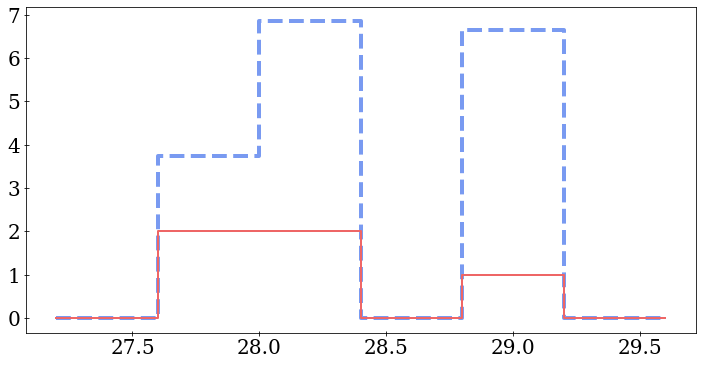

In [97]:

binw = np.arange(27,30,0.4)

histp = list(np.histogram(mag2,bins=binw))

mids = 0.5*(binw[1:] + binw[:-1])

corr = histp[0]/f1(mids)
##corr,mids,f1(mids)
histp[0], corr
fig,ax = plt.subplots(figsize=(12,6))
plt.step(mids,corr,color='#799af1',linestyle='dashed',linewidth=4)
plt.step(mids,histp[0])
#plt.ylim(0,5)


In [98]:
#binw = np.arange(26.5,28.85,0.35)

def PNLF_analytic(m5007, mag, c1):
    return c1*np.exp(-0.302*mag)*np.exp(0.302*m5007)*(1.- np.exp(3*(-4.51 + mag - m5007)))

def PNLF_analytic2(m5007, c1, c2, mag):
    return c1*np.exp(-c2*mag)*np.exp(c2*m5007)*(1.- np.exp(3*(-4.51 + mag - m5007)))


def PNLFfix(m5007):
    mag = 31.33
    c1 = 7
    return c1*np.exp(-0.302*mag)*np.exp(0.302*m5007)*(1.- np.exp(3*(-4.51 + mag - m5007)))


#histp2 = list(np.histogram(mag2,bins=binw))
cm = f1(binw)
corr = histp[0]/f1(mids)
#mids2 = 0.5*(binw[1:] +binw[:-1])
condition = mids < 28.4
popt,pcov = curve_fit(PNLF_analytic,mids[condition],corr[condition],p0=[30.5,0.8])
popt2,pcov2 = curve_fit(PNLF_analytic2,mids[condition],corr[condition],p0=[20,0.3,30],bounds=([0,0,0],[20,10,100]))
#popt3,pcov3 = curve_fit(PNLF,mids[condition],corr[condition],p0=[0.8])

print(popt,popt2)

[31.78011486 14.54080742] [19.99997212  2.3719106  28.83959672]


In [99]:
class PNLF(object):
    """
    This function calculates the PNLF given magnitude data of PNe (organised in the PN tracers class)
    In case color or detection completeness are not known, put 1
    """
    def __init__(self, PNe, galaxy, Ly_alpha, mag_bins, color_completeness,
        detection_completeness, Ntot = 15, normalized = True):
        self.PNe = PNe
        self.galaxy = galaxy
        self.Ly_alpha = Ly_alpha
        self.mag_bins = mag_bins
        self.color_completeness = color_completeness
        self.detection_completeness = detection_completeness
        self.Nsample = len(self.PNe.mag)
        self.normalized = normalized
        self.Ntot = Ntot
        self.r = 1.#self.Nsample/float(self.Ntot)


    @property
    def N_PN(self):
        N_PN, bin_edges = np.histogram(self.PNe.mag, self.mag_bins)
        return N_PN

    @property
    def bin_edges(self):
        N_PN, bin_edges = np.histogram(self.PNe.mag, self.mag_bins)
        return bin_edges

    @property
    def bin_centers(self):
        return  0.5*(self.bin_edges[1:] + self.bin_edges[:-1])
        

    @property
    def bin_width(self):
        return self.bin_edges[1:] - self.bin_edges[:-1]

    @property
    def N_Ly(self):
        interp = interpolate.interp1d(self.Ly_alpha.m_range, self.Ly_alpha.logN)
        return 10**(interp(self.bin_centers))*self.bin_width

    @property
    def N_corr(self):
        return self.N_PN/self.bin_width/self.color_completeness/self.detection_completeness

    @property
    def N_PN_Lya(self):
        Ly_contr = self.r*self.N_Ly
        if self.normalized == True:
            return (self.N_corr - Ly_contr)/self.Nsample
        else:
            return self.N_corr - Ly_contr

    @property
    def error(self):
        err_poiss= self.N_PN/(self.bin_width*self.color_completeness*self.detection_completeness)**2
        err_Ly =  self.bin_width*self.Ly_alpha.bin_width*self.r*self.N_Ly
        if self.normalized == True:
            return np.sqrt(err_poiss )/self.Nsample
        else:
            return np.sqrt(err_poiss )

    @property
    def LF(self):
        return np.log10(self.N_PN)

    @property
    def log_err(self):
        low = np.log10(self.N_PN) - np.log10(self.N_PN - self.error)
        high = np.log10(self.N_PN + self.error) - np.log10(self.N_PN)
        return [low, high]

    
class galaxy(object):
    def __init__(self, RA_center, dec_center, PA, ell, r_ell, distance):
        self.RA_center = coords.Angle(RA_center, unit = u.hourangle)
        self.dec_center = coords.Angle(dec_center, unit = u.deg)
        self.PA = u.Quantity(0.5*np.pi, u.radian) - u.Quantity(PA, u.radian)
        self.ell = ell
        self.r_ell = u.Quantity(r_ell, unit = u.arcsecond)
        self.distance = distance

    @property
    def distance_modulus(self):
        return 5.*np.log10(self.distance) - 5.

def area_ellipse(ell, a_arr):
    A = [np.pi*(1.-ell)*(a_arr[0]**2)]
    for i in range(1,len(a_arr)):
        A.append(np.pi*(1.-ell)*(a_arr[i]**2 - a_arr[i-1]**2))
    return np.array(A)

class PNe(object):
    def __init__(self, ID, RA, dec, mag, vel, vel_err, galaxy):
        self.ID = ID
        self.RA = coords.Angle(RA, unit = u.hourangle)
        self.dec = coords.Angle(dec, unit = u.deg)
        self.mag = mag
        self.vel = vel
        self.vel_err = vel_err
        self.galaxy = galaxy

    @property
    def RA_shifted(self):
        return self.RA - self.galaxy.RA_center

    @property
    def dec_shifted(self):
        return self.dec - self.galaxy.dec_center

    @property
    def r_major(self):
# RA and dec are already shifted wrt center coordinates
# RA, dec --> astropy angles
# output in degrees
        q = 1. - self.galaxy.ell
        x = self.RA_shifted.degree * np.cos(self.galaxy.PA) - self.dec_shifted.degree
        y = self.RA_shifted.degree * np.sin(self.galaxy.PA) + self.dec_shifted.degree 
        return np.sqrt(x**2 + y**2/q**2)

    @property
    def radius(self):
        return np.sqrt(self.RA_shifted.degree**2 + self.dec_shifted.degree**2)

    @property
    def angle(self):
        x = self.RA_shifted.degree * np.cos(self.galaxy.PA) - self.dec_shifted.degree 
        y = self.RA_shifted.degree * np.sin(self.galaxy.PA) + self.dec_shifted.degree 
        angl = coords.Angle(np.arctan2(y,x), unit = u.rad)
        return angl
    

class Ly_alpha(object):
    """
    This is the luminosity function of Ly-alpha emitters at z = 3.1, scaled to our survey area
    and with fluxes converted to F_5007 / m_5007. This function can be interpolated in order
    to determine the number of Ly-alpha emitters per magnitude bin of the PNLF.
     """
    def __init__(self, L_star = 10**42.66, L_range = 10**np.linspace(41, 44, 40),
        alpha = -1.36, phi0 = 1.28e-3, area_conversion = 8.666666666666e58,
        frac_area = 0.75, area = 1.686e5, bin_width = 0.2):
        self.L_star = L_star
        self.L_range = L_range
        self.alpha = alpha
        self.phi0 = phi0
        self.area_conversion = area_conversion
        self.frac_area = frac_area
        self.area = area #u.Mpc
        self.bin_width = 0.2

    def Schechter(self, x):
        return self.phi0*x**self.alpha*np.exp(-x)*self.frac_area*self.area

    @property
    def logN(self):
        return np.log10(self.Schechter(self.L_star/self.L_range))

    def to_m5007(self, flux):
        return -2.5*np.log10(flux) - 13.74

    @property
    def m_range(self):
        return self.to_m5007(self.L_range/self.area_conversion)[::-1]



In [100]:
NGC4374 = galaxy(RA_center =186.2655    * u.deg, dec_center = 12.886 ,
                PA = 60 * u.deg, ell = 0, r_ell = 10, distance = 18.5e3)


ID_number = list(range(len(pne)))
RAJ2000 = pne[:,2]
decJ2000 = pne[:,3]
magOIII = pne[:,5]
velfake = pne[:,4]

ly = Ly_alpha(1)
PNe = PNe(ID = ID_number, RA = RAJ2000 * u.deg, dec = decJ2000 * u.deg, mag = magOIII, vel = velfake, galaxy = NGC4374, vel_err= velfake)

In [104]:
obj_pn = PNLF(PNe, galaxy, ly, histp[1], 1, f1(histp[1][0:7]), Ntot = 15, normalized = True)

In [105]:
errores = obj_pn.error
errores

array([0.        , 0.        , 1.1348004 , 1.66736862, 0.        ,
       3.21758911, 0.        ])

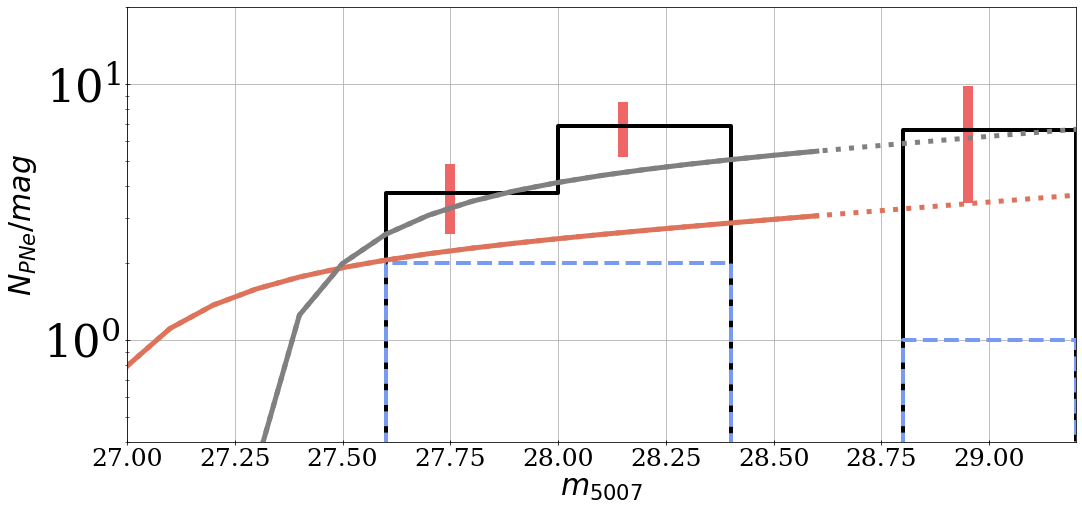

In [108]:
fig,ax = plt.subplots(figsize=(17,8))
plt.grid(True)
plt.step(mids,corr,color='black',linewidth=4)
plt.step(mids,histp[0],color='#799af1',linestyle='dashed',linewidth=4)

#plt.hist(mag,18,color='#799af1',density=True)
plt.xlim(27,29.2)
plt.xlabel('$m_{5007}$',fontsize=30)
plt.ylabel('$N_{PNe}/mag$',fontsize=30)
plt.ylim(0.4,20)
x0 = np.arange(26,28.7,0.1)
plt.plot(x0,PNLFfix(x0),'r-',label='fit',c='#de735b',linewidth=5)
plt.plot(x0,PNLF_analytic(x0,*popt),'r-',label='fit',c='grey',linewidth=5)
plt.yticks(fontsize=45)
plt.xticks(fontsize=25)

plt.errorbar(mids-0.25, corr, yerr = errores, fmt = 'none', linewidth=10)

x0 = np.arange(27,29.5,0.1)
plt.plot(x0,PNLFfix(x0),'r:',label='fit',c='#de735b',linewidth=5)
plt.plot(x0,PNLF_analytic(x0,*popt),'r:',label='fit',c='grey',linewidth=5)

plt.yscale('log')

plt.savefig('pnlf2.png',bbox_inches='tight')

TypeError: __init__() missing 5 required positional arguments: 'galaxy', 'Ly_alpha', 'mag_bins', 'color_completeness', and 'detection_completeness'

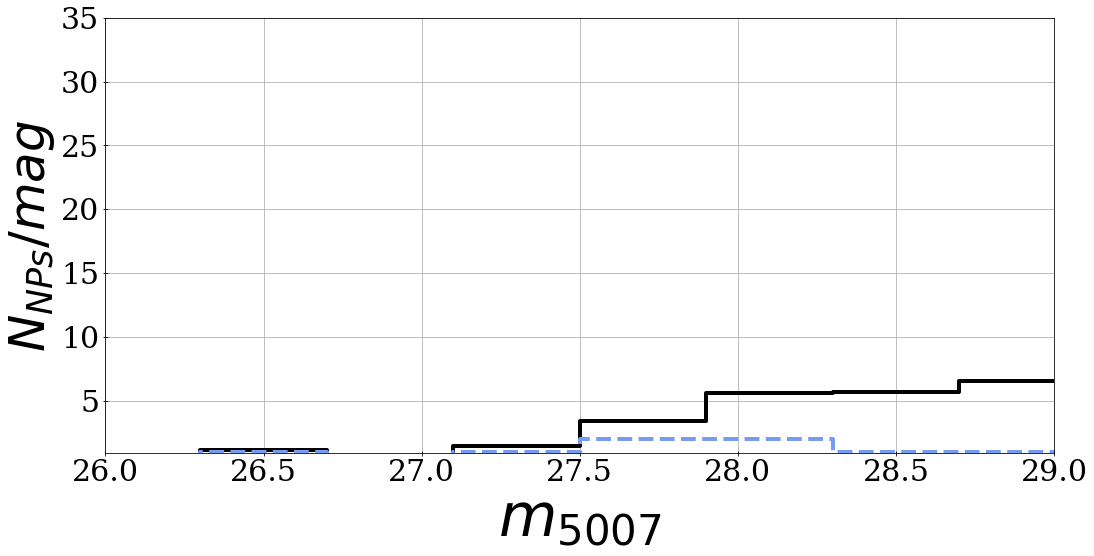

In [55]:
fig,ax = plt.subplots(figsize=(17,8))
plt.grid(True)
plt.step(mids,corr,color='black',linewidth=4,label='Completeness corrected')
plt.step(mids,histp[0],color='#799af1',linestyle='dashed',linewidth=4,label='Raw')

#plt.hist(mag,18,color='#799af1',density=True)
plt.xlim(26,29)
plt.xlabel('$m_{5007}$',fontsize=60)
plt.ylabel('$N_{NPs}/mag$',fontsize=50)
plt.ylim(0.9,35)
x0 = np.arange(26,29,0.1)
#plt.plot(x0,PNLF_analytic2(x0,*popt2),'r-',c='#de735b',linewidth=5,label='Variable slope')
plt.plot(x0,PNLF(x0),'r-',c='grey',linewidth=5,label='Fixed slope')
plt.yticks(fontsize=45)
plt.xticks(fontsize=45)

#plt.errorbar((mids-0.25), histp[0]/compl['detection_completeness'], yerr = errores, fmt = 'none', linewidth=10)

x0 = np.arange(26,29.5,0.1)
#plt.plot(x0,PNLF_analytic2(x0,*popt2),'r:',c='#de735b',linewidth=5)
plt.plot(x0,PNLF_analytic(x0,*popt),'r:',c='grey',linewidth=5)

plt.yscale('log')
plt.legend(mode='expand',ncol=2)
plt.savefig('pnlf2.png',bbox_inches='tight')

In [336]:
import scipy.integrate as integrate

In [339]:
integrate.quad(PNLF,26.09,28.59)[0]/integrate.quad(PNLF,26.09,28.1)[0]

1.40399208833806

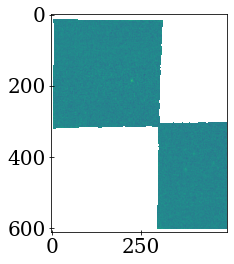

In [51]:
hdu = fits.open('../ngc4594/slices/a/ngc4594-a-0_slinan.fits')
plt.imshow(hdu[1].data)

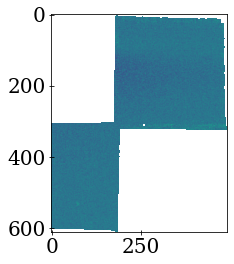

In [54]:
hdu = fits.open('../ngc4594/slices/c/ngc4594-c-10_slinan.fits')
plt.imshow(hdu[1].data)

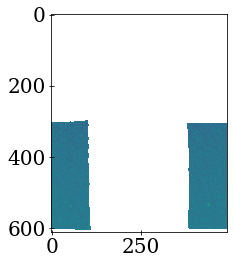

In [55]:
hdu = fits.open('../ngc4594/slices/b/ngc4594-b-10_slinan.fits')
plt.imshow(hdu[1].data)